# A7 Part 2, Part 1: Building and Experimenting With Our Small Language Model
**INFO 490 MG, Team 2 (Unleased)**

This notebook reuses the **Week 7 Small Language Model** from class (`Script-1-Build-SLM-Demo-Fixed.ipynb`). The tokenizer, Transformer block, model class, loss, training loop and `generate_text` function below are copied from the class notebook unchanged. The only things we change are the **Cell 2 architecture settings** and the generation temperature, as the assignment allows.

**How to run (Google Colab):** Runtime > Run all. No GPU is needed; like the class notebook, everything runs on the CPU.
All 6 training runs (baseline + 5 experiments) use the class "classroom" preset of 30,000 steps, which takes about 15 to 30 minutes in total on a Colab CPU (the largest model, Experiment 5, takes the longest).
Results are saved after every run. If Colab disconnects, upload `slm_results/` back (or keep the runtime alive) and Run all again; finished runs are skipped.

**Analogy:** think of the model as a small kitchen. Embedding size is how big each cutting board is, attention heads are how many cooks look at the order at once, layers are how many prep stations the dish passes through, and the feed-forward size is how big each station's workbench is. We rebuild the kitchen 6 ways, cook the same recipe (training corpus) for the same time (30,000 steps), and taste the result (generated text).

## Setup (class Cells 0 and 1)

In [1]:
!pip -q install psutil
# ============================================================
# CELL 0: TRAINING PRESETS (from class, unchanged)
# ============================================================
TRAINING_MODE = "classroom"
TRAINING_PRESETS = {"quick": 50, "classroom": 30000, "extended": 1000}
TRAINING_STEPS = TRAINING_PRESETS[TRAINING_MODE]
print("Training mode:", TRAINING_MODE)
print("Training steps:", TRAINING_STEPS)

Training mode: classroom
Training steps: 30000


In [2]:
# ============================================================
# CELL 1: IMPORT LIBRARIES AND CONFIGURE THE ENVIRONMENT (from class)
# ============================================================
import math, random, time, platform, json, os
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Keep execution predictable (same as class).
torch.set_num_threads(2)

# The class notebook runs on the CPU. We keep the CPU for every run so training times are comparable.
DEVICE = torch.device("cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Machine:", platform.platform(), "| CPU cores:", psutil.cpu_count(logical=True),
      "| RAM GB:", round(psutil.virtual_memory().total / 1e9, 1))

PyTorch: 2.11.0+cpu
Device: cpu
Machine: Linux-6.6.159+-x86_64-with-glibc2.39 | CPU cores: 2 | RAM GB: 13.6


## Cell 2: Configure the Transformer architecture (baseline values)
These are the original class values. The experiment runner further down changes **only** `EMBEDDING_DIM`, `NUM_HEADS`, `NUM_LAYERS` and `FEEDFORWARD_DIM` for each experiment. Context length, batch size, learning rate, training steps, corpus and generation settings stay the same for every run.

In [3]:
# ============================================================
# CELL 2: CONFIGURE THE TRANSFORMER ARCHITECTURE (class baseline)
# ============================================================
BATCH_SIZE = 16
CONTEXT_LENGTH = 32
EMBEDDING_DIM = 48
NUM_HEADS = 2
NUM_LAYERS = 1
FEEDFORWARD_DIM = 192
LEARNING_RATE = 0.001

assert EMBEDDING_DIM % NUM_HEADS == 0
HEAD_DIM = EMBEDDING_DIM // NUM_HEADS
print("Embedding dimension:", EMBEDDING_DIM, "| Attention heads:", NUM_HEADS, "| Dimension per head:", HEAD_DIM)
print("Transformer blocks:", NUM_LAYERS, "| Feed-forward:", FEEDFORWARD_DIM, "| Context length:", CONTEXT_LENGTH)

# Generation settings shared by every experiment (class Cell 14B uses this prompt and temperature)
PROMPT = "students "
MAX_NEW_TOKENS = 60
GEN_TEMPERATURE = 0.7

Embedding dimension: 48 | Attention heads: 2 | Dimension per head: 24
Transformer blocks: 1 | Feed-forward: 192 | Context length: 32


## Training data and tokenizer (class Cells 3, 4, 5A, 6B, unchanged)

In [4]:
# CELL 3: CREATE OR LOAD TRAINING DATA (from class)
CORPUS_PATH = Path("training_corpus.txt")
if not CORPUS_PATH.exists():
    sentences = [
        "students build django applications.",
        "students learn python programming.",
        "students develop artificial intelligence systems.",
        "language models predict the next token.",
        "transformers use attention mechanisms.",
        "neural networks learn from training data.",
        "machine learning models contain parameters.",
        "the professor teaches artificial intelligence.",
        "students create innovative startup applications.",
        "django applications use models and views.",
        "training changes the weights of a neural network.",
        "inference uses previously learned parameters.",
        "the university offers courses in informatics.",
        "students experiment with language models.",
        "artificial intelligence can generate text.",
        "the model predicts characters using probabilities.",
        "attention helps models use contextual information.",
        "python is useful for machine learning research.",
        "the students are building useful software products.",
        "small language models can run on local computers."
    ]
    text = "\n".join(sentences)
    CORPUS_PATH.write_text((text + "\n") * 100, encoding="utf-8")

text = CORPUS_PATH.read_text(encoding="utf-8")
print("Characters in corpus:", len(text), "(the class corpus has 90,300)")
print(text[:200])

Characters in corpus: 90300 (the class corpus has 90,300)
students build django applications.
students learn python programming.
students develop artificial intelligence systems.
language models predict the next token.
transformers use attention mechanisms.



In [5]:
# CELL 4: BUILD OUR OWN TOKENIZER (character level, from class)
chars = sorted(set(text))
VOCAB_SIZE = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(s):
    """Convert a string into a list of character token IDs."""
    return [stoi[ch] for ch in s]

def decode(ids):
    """Convert character token IDs back into a string."""
    return "".join(itos[int(i)] for i in ids)

# CELL 5A: CONVERT TRAINING TEXT INTO TENSORS, 90/10 split (from class)
data = torch.tensor(encode(text), dtype=torch.long)
split = int(0.9 * len(data))
train_data = data[:split]
val_data = data[split:]

# CELL 6B: CREATE MINI-BATCHES (from class)
def get_batch(source):
    """Sample random input/target sequences from a token tensor."""
    starts = torch.randint(0, len(source) - CONTEXT_LENGTH, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LENGTH] for i in starts])
    y = torch.stack([source[i + 1:i + CONTEXT_LENGTH + 1] for i in starts])
    return x.to(DEVICE), y.to(DEVICE)

print("Vocabulary size:", VOCAB_SIZE, "| Training tokens:", len(train_data), "| Validation tokens:", len(val_data))

Vocabulary size: 27 | Training tokens: 81270 | Validation tokens: 9030


## The Transformer (class Cells 9A and 9B, unchanged)

In [6]:
# CELL 9A: BUILD A TRANSFORMER BLOCK (from class)
class TransformerBlock(nn.Module):

    def __init__(self, embedding_dim, num_heads, feedforward_dim):
        super().__init__()
        self.attention = nn.MultiheadAttention(
            embed_dim=embedding_dim,
            num_heads=num_heads,
            dropout=0.0,
            batch_first=True)
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)
        self.feedforward = nn.Sequential(
            nn.Linear(embedding_dim, feedforward_dim),
            nn.ReLU(),
            nn.Linear(feedforward_dim, embedding_dim))

    def forward(self, x):
        T = x.shape[1]
        mask = torch.triu(torch.ones(T, T, device=x.device, dtype=torch.bool), diagonal=1)
        normalized = self.ln1(x)
        attended, _ = self.attention(normalized, normalized, normalized, attn_mask=mask, need_weights=False)
        x = x + attended
        x = x + self.feedforward(self.ln2(x))
        return x


# CELL 9B: BUILDING OUR COMPLETE TINY TRANSFORMER (from class)
class TinyTransformerLM(nn.Module):

    def __init__(self, vocab_size, embedding_dim, num_heads, num_layers, feedforward_dim, context_length):
        super().__init__()
        self.context_length = context_length
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)
        self.position_embedding = nn.Embedding(context_length, embedding_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embedding_dim, num_heads, feedforward_dim)
            for _ in range(num_layers)
        ])
        self.ln_final = nn.LayerNorm(embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, input_ids):
        B, T = input_ids.shape
        if T > self.context_length:
            raise ValueError("Input sequence exceeds context length.")
        positions = torch.arange(T, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.ln_final(x)
        return self.output(x)

## Generation, loss and evaluation (class Cells 12A, 13A, 14G, unchanged)

In [7]:
# CELL 12A: TEXT GENERATION (from class)
@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=100, temperature=1.0):
    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")
    was_training = model.training
    model.eval()
    ids = torch.tensor([encode(prompt)], dtype=torch.long, device=DEVICE)
    for _ in range(max_new_tokens):
        context = ids[:, -model.context_length:]
        logits = model(context)
        next_logits = logits[:, -1, :] / temperature
        probabilities = F.softmax(next_logits, dim=-1)
        next_id = torch.multinomial(probabilities, num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)
    if was_training:
        model.train()
    return decode(ids[0].tolist())

# CELL 13A: CROSS-ENTROPY LOSS (from class)
def calculate_loss(logits, targets):
    B, T, V = logits.shape
    return F.cross_entropy(logits.reshape(B * T, V), targets.reshape(B * T))

# CELL 14G: EVALUATE (from class)
@torch.no_grad()
def evaluate(model, source, batches=20):
    model.eval()
    losses = []
    for _ in range(batches):
        x, y = get_batch(source)
        losses.append(calculate_loss(model(x), y).item())
    model.train()
    return sum(losses) / len(losses)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Steps 1.1 and 1.2: Run the baseline and the 5 architecture experiments
Each run does exactly what the class notebook does after you edit Cell 2 and run it:
1. Set the Cell 2 architecture values.
2. Build a **newly initialized** model with `torch.manual_seed(SEED)` (class Cell 10A).
3. Count trainable parameters (class Cell 10B).
4. Train for `TRAINING_STEPS` steps with AdamW at the same learning rate, batch size and context length (class Cells 13C and 14A).
5. Generate text from the same prompt with the same settings (class Cell 14B).

Two small additions keep the comparison fair: the random seed is reset right before training so every run sees the same sequence of training batches, and it is reset again before generating so every run samples with the same random numbers. Each trained model is saved as a checkpoint in the class format (class Cell 14D).

The baseline and Experiment 2 use identical settings, so they should give the same parameter count and loss. That is a useful check that the runs are reproducible.

In [8]:
EXPERIMENTS = {
    "Baseline": dict(embedding_dim=48, num_heads=2, num_layers=1, feedforward_dim=192),
    "1":        dict(embedding_dim=24, num_heads=2, num_layers=1, feedforward_dim=96),
    "2":        dict(embedding_dim=48, num_heads=2, num_layers=1, feedforward_dim=192),
    "3":        dict(embedding_dim=48, num_heads=4, num_layers=1, feedforward_dim=192),
    "4":        dict(embedding_dim=48, num_heads=2, num_layers=2, feedforward_dim=192),
    "5":        dict(embedding_dim=96, num_heads=4, num_layers=2, feedforward_dim=384),
}

OUT = Path("slm_results"); OUT.mkdir(exist_ok=True)
RESULTS_CSV = OUT / "architecture_results.csv"

def run_experiment(name, cfg):
    global EMBEDDING_DIM, NUM_HEADS, NUM_LAYERS, FEEDFORWARD_DIM
    # Step 1: change the Cell 2 values
    EMBEDDING_DIM, NUM_HEADS, NUM_LAYERS, FEEDFORWARD_DIM = (cfg["embedding_dim"], cfg["num_heads"],
                                                              cfg["num_layers"], cfg["feedforward_dim"])
    assert EMBEDDING_DIM % NUM_HEADS == 0

    # Step 2: newly initialized model (class Cell 10A)
    torch.manual_seed(SEED)
    model = TinyTransformerLM(vocab_size=VOCAB_SIZE, embedding_dim=EMBEDDING_DIM, num_heads=NUM_HEADS,
                              num_layers=NUM_LAYERS, feedforward_dim=FEEDFORWARD_DIM,
                              context_length=CONTEXT_LENGTH).to(DEVICE)

    # Step 3: trainable parameters (class Cell 10B)
    total_parameters = count_parameters(model)

    # Step 4: train (class Cells 13C and 14A)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
    torch.manual_seed(SEED)                     # same batch order for every run
    model.train()
    loss_history = []
    start_time = time.perf_counter()
    for step in range(TRAINING_STEPS):
        xb, yb = get_batch(train_data)
        optimizer.zero_grad()
        logits = model(xb)
        loss = calculate_loss(logits, yb)
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
        if step % 5000 == 0 or step == TRAINING_STEPS - 1:
            print(f"  [{name}] Step {step + 1:>5}/{TRAINING_STEPS} | Loss: {loss.item():.4f}")
    elapsed = time.perf_counter() - start_time

    # Held-out check (class Cell 14G). Note: the class corpus repeats sentences, so this is not true generalization.
    torch.manual_seed(SEED)
    val_loss = evaluate(model, val_data)

    # Step 5: generate with the same prompt and settings (class Cell 14B)
    torch.manual_seed(SEED)
    generated = generate_text(model, PROMPT, max_new_tokens=MAX_NEW_TOKENS, temperature=GEN_TEMPERATURE)

    # Save checkpoint in the class format (class Cell 14D)
    ckpt_path = OUT / f"slm_{name.lower()}.pt"
    torch.save({"model_state": model.state_dict(), "vocab": chars,
                "config": {"embedding_dim": EMBEDDING_DIM, "num_heads": NUM_HEADS, "num_layers": NUM_LAYERS,
                           "feedforward_dim": FEEDFORWARD_DIM, "context_length": CONTEXT_LENGTH}}, ckpt_path)
    np.save(OUT / f"loss_{name.lower()}.npy", np.array(loss_history))

    return {"Experiment": name, "Embedding Dimension": EMBEDDING_DIM, "Attention Heads": NUM_HEADS,
            "Transformer Layers": NUM_LAYERS, "Feed-Forward Dimension": FEEDFORWARD_DIM,
            "Context Length": CONTEXT_LENGTH, "Batch Size": BATCH_SIZE, "Learning Rate": LEARNING_RATE,
            "Training Steps": TRAINING_STEPS, "Total Parameters": total_parameters,
            "Final Training Loss": round(loss_history[-1], 4),
            "Avg Loss Last 500 Steps": round(float(np.mean(loss_history[-500:])), 4),
            "Validation Loss": round(val_loss, 4), "Training Time (s)": round(elapsed, 1),
            "Generated Text": generated, "Checkpoint": str(ckpt_path)}

done = pd.read_csv(RESULTS_CSV)["Experiment"].astype(str).tolist() if RESULTS_CSV.exists() else []
for name, cfg in EXPERIMENTS.items():
    if name in done:
        print("skip (already done):", name); continue
    print(f"\n=== Experiment {name}: {cfg} ===")
    row = run_experiment(name, cfg)
    pd.DataFrame([row]).to_csv(RESULTS_CSV, mode="a", header=not RESULTS_CSV.exists(), index=False)
    print(f"  Parameters {row['Total Parameters']:,} | final loss {row['Final Training Loss']} | "
          f"time {row['Training Time (s)']} s\n  Text: {row['Generated Text']!r}")
print("\nAll runs saved to", RESULTS_CSV)


=== Experiment Baseline: {'embedding_dim': 48, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 192} ===
  [Baseline] Step     1/30000 | Loss: 3.4406
  [Baseline] Step  5001/30000 | Loss: 0.1844
  [Baseline] Step 10001/30000 | Loss: 0.1524
  [Baseline] Step 15001/30000 | Loss: 0.1255
  [Baseline] Step 20001/30000 | Loss: 0.1526
  [Baseline] Step 25001/30000 | Loss: 0.1403
  [Baseline] Step 30000/30000 | Loss: 0.1346
  Parameters 32,523 | final loss 0.1346 | time 200.6 s
  Text: 'students are building useful software products.\nsmall language models'

=== Experiment 1: {'embedding_dim': 24, 'num_heads': 2, 'num_layers': 1, 'feedforward_dim': 96} ===
  [1] Step     1/30000 | Loss: 3.4287
  [1] Step  5001/30000 | Loss: 0.2198
  [1] Step 10001/30000 | Loss: 0.1590
  [1] Step 15001/30000 | Loss: 0.1526
  [1] Step 20001/30000 | Loss: 0.1513
  [1] Step 25001/30000 | Loss: 0.1474
  [1] Step 30000/30000 | Loss: 0.1389
  Parameters 9,363 | final loss 0.1389 | time 155.3 s
  Text: 'students a

### Step 1.1 Baseline table

In [9]:
res = pd.read_csv(RESULTS_CSV, dtype={"Experiment": str})
b = res[res["Experiment"] == "Baseline"].iloc[0]
baseline_table = pd.DataFrame({
    "Configuration": ["Embedding Dimension", "Attention Heads", "Transformer Layers", "Feed-Forward Dimension",
                      "Context Length", "Batch Size", "Learning Rate", "Total Trainable Parameters",
                      "Final Training Loss", "Training Time", "Generated Text"],
    "Original Value": [b["Embedding Dimension"], b["Attention Heads"], b["Transformer Layers"], b["Feed-Forward Dimension"],
                       b["Context Length"], b["Batch Size"], b["Learning Rate"], f"{int(b['Total Parameters']):,}",
                       b["Final Training Loss"], f"{b['Training Time (s)']} s ({TRAINING_STEPS:,} steps)", b["Generated Text"]]})
baseline_table.to_csv(OUT / "baseline_table.csv", index=False)
pd.set_option("display.max_colwidth", None)
baseline_table

,Configuration,Original Value
0,Embedding Dimension,48
1,Attention Heads,2
2,Transformer Layers,1
3,Feed-Forward Dimension,192
4,Context Length,32
5,Batch Size,16
6,Learning Rate,0.001
7,Total Trainable Parameters,"32,523"
8,Final Training Loss,0.1346
9,Training Time,"200.6 s (30,000 steps)"


### Step 1.2 Experiment table

In [10]:
exp_table = res[res["Experiment"] != "Baseline"][["Experiment", "Embedding Dimension", "Attention Heads", "Transformer Layers",
                                                  "Feed-Forward Dimension", "Total Parameters", "Final Training Loss",
                                                  "Avg Loss Last 500 Steps", "Validation Loss", "Training Time (s)", "Generated Text"]]
exp_table.to_csv(OUT / "experiment_table.csv", index=False)
exp_table

,Experiment,Embedding Dimension,Attention Heads,Transformer Layers,Feed-Forward Dimension,Total Parameters,Final Training Loss,Avg Loss Last 500 Steps,Validation Loss,Training Time (s),Generated Text
1,1,24,2,1,96,9363,0.1389,0.1451,0.1410,155.3,students are building useful software products.\nsmall language models
2,2,48,2,1,192,32523,0.1346,0.1365,0.1339,196.6,students are building useful software products.\nsmall language models
3,3,48,4,1,192,32523,0.1275,0.1355,0.1336,208.9,students are building useful software products.\nsmall language models
4,4,48,2,2,192,60795,0.1253,0.1305,0.1320,330.6,students are building useful software products.\nsmall language models
5,5,96,4,2,384,232155,0.1266,0.1262,0.1264,626.6,students are building useful software products.\nsmall language models


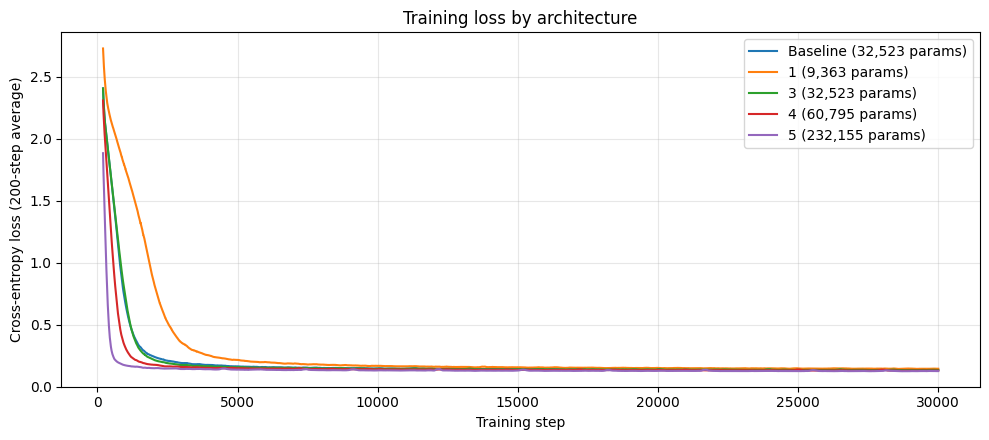

In [11]:
# Training-loss curves (class Cell 14F), smoothed over 200 steps so the runs can be compared on one chart
plt.figure(figsize=(10, 4.5))
for name in EXPERIMENTS:
    f = OUT / f"loss_{name.lower()}.npy"
    if f.exists() and name != "2":   # Experiment 2 has the same settings as the baseline
        h = pd.Series(np.load(f)).rolling(200).mean()
        plt.plot(h, label=f"{name} ({int(res.loc[res['Experiment'] == name, 'Total Parameters'].iloc[0]):,} params)")
plt.xlabel("Training step"); plt.ylabel("Cross-entropy loss (200-step average)")
plt.title("Training loss by architecture"); plt.ylim(bottom=0); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig(OUT / "loss_curves.png", dpi=150); plt.show()

### A closer look: learning speed and text quality
After 30,000 steps the class corpus (20 sentences repeated 100 times) is almost memorized, so every model can end up printing the same corpus sentence from one sample. Two extra measurements make the differences visible. Both come from the saved loss histories and checkpoints, so nothing is retrained.
- **Learning speed:** average training loss around step 1,000 and step 5,000, and the first step where the 200-step average loss drops below 0.5.
- **Text quality over 5 samples:** share of generated words that are real corpus words, and share of complete generated lines that exactly match a corpus sentence.

In [12]:
CORPUS_SENTENCES = set(l.strip() for l in text.splitlines() if l.strip())
CORPUS_WORDS = {w.strip(".") for w in text.split()}

def load_ckpt(path):
    s = torch.load(path, map_location=DEVICE, weights_only=True); c = s["config"]
    m = TinyTransformerLM(vocab_size=len(s["vocab"]), embedding_dim=c["embedding_dim"], num_heads=c["num_heads"],
                          num_layers=c["num_layers"], feedforward_dim=c["feedforward_dim"],
                          context_length=c["context_length"]).to(DEVICE)
    m.load_state_dict(s["model_state"]); m.eval(); return m

def text_quality(model, n=5, temperature=GEN_TEMPERATURE, max_new_tokens=100):
    torch.manual_seed(SEED)
    samples = [generate_text(model, PROMPT, max_new_tokens=max_new_tokens, temperature=temperature) for _ in range(n)]
    words = [w.strip(".") for s in samples for w in s.split()[:-1]]   # drop the unfinished last word
    lines = [l.strip() for s in samples for l in s.split("\n")[:-1] if l.strip()]   # drop the unfinished last line
    return {"Real-word share": round(sum(w in CORPUS_WORDS for w in words) / max(len(words), 1), 2),
            "Exact corpus lines": f"{sum(l in CORPUS_SENTENCES for l in lines)}/{len(lines)}",
            "Example sample": samples[1]}

extra = []
for name in EXPERIMENTS:
    r = res[res["Experiment"] == name].iloc[0]
    h = pd.Series(np.load(OUT / f"loss_{name.lower()}.npy")).rolling(200).mean()
    below = h[h < 0.5]
    extra.append({"Experiment": name, "Total Parameters": int(r["Total Parameters"]),
                  "Loss @ step 1,000": round(h.iloc[999], 3), "Loss @ step 5,000": round(h.iloc[4999], 3),
                  "First step below 0.5": int(below.index[0]) + 1 if len(below) else None,
                  **text_quality(load_ckpt(r["Checkpoint"]))})
extra_table = pd.DataFrame(extra)
extra_table.to_csv(OUT / "learning_speed_and_quality.csv", index=False)
extra_table

,Experiment,Total Parameters,"Loss @ step 1,000","Loss @ step 5,000",First step below 0.5,Real-word share,Exact corpus lines,Example sample
0,Baseline,32523,0.671,0.164,1166,1.0,7/10,students create innovative startup applications.\ndjango applications use models and views.\ntraining changes t
1,1,9363,1.756,0.216,2544,1.0,5/10,students create innovative startup applications.\ndjango applications use models and views.\ntraining changes t
2,2,32523,0.671,0.164,1166,1.0,7/10,students create innovative startup applications.\ndjango applications use models and views.\ntraining changes t
3,3,32523,0.717,0.157,1175,1.0,9/10,students create innovative startup applications.\ndjango applications use models and views.\ntraining changes t
4,4,60795,0.315,0.149,787,1.0,7/10,students create innovative startup applications.\ndjango applications use models and views.\ntraining changes t
5,5,232155,0.172,0.138,407,1.0,9/10,students create innovative startup applications.\ndjango applications use models and views.\ntraining changes t


### Select one checkpoint for Parts 2 to 4
The rule: pick the experiment with the **lowest average training loss over the last 500 steps**, which is steadier than the single final-step loss. We also read its generated text to confirm it looks best. The chosen model is copied to `slm_results/selected_slm.pt`. RAG, fine-tuning and the final comparison must all start from this one file.

If the generated text tells a different story from the loss, set `SELECTED` by hand and say why in the analysis.

In [13]:
SELECTED = res.loc[res["Avg Loss Last 500 Steps"].idxmin(), "Experiment"]
# SELECTED = "5"   # uncomment to override by hand
row = res[res["Experiment"] == SELECTED].iloc[0]
import shutil
shutil.copy(row["Checkpoint"], OUT / "selected_slm.pt")
json.dump({"selected_experiment": str(SELECTED), "config": EXPERIMENTS[str(SELECTED)],
           "context_length": CONTEXT_LENGTH, "training_steps": TRAINING_STEPS, "seed": SEED},
          open(OUT / "selected_slm.json", "w"), indent=2)
print("Selected experiment:", SELECTED, EXPERIMENTS[str(SELECTED)])
print("Parameters:", f"{int(row['Total Parameters']):,}", "| avg loss last 500:", row["Avg Loss Last 500 Steps"])
print("Saved slm_results/selected_slm.pt")

Selected experiment: 5 {'embedding_dim': 96, 'num_heads': 4, 'num_layers': 2, 'feedforward_dim': 384}
Parameters: 232,155 | avg loss last 500: 0.1262
Saved slm_results/selected_slm.pt


### How teammates load the selected checkpoint (class Cell 14E)
Run the tokenizer and model-class cells above first, then:
```python
saved = torch.load("slm_results/selected_slm.pt", map_location=DEVICE, weights_only=True)
cfg = saved["config"]
slm = TinyTransformerLM(vocab_size=len(saved["vocab"]), embedding_dim=cfg["embedding_dim"], num_heads=cfg["num_heads"],
                        num_layers=cfg["num_layers"], feedforward_dim=cfg["feedforward_dim"],
                        context_length=cfg["context_length"]).to(DEVICE)
slm.load_state_dict(saved["model_state"]); slm.eval()
```
The vocabulary in the checkpoint must match the tokenizer, so any RAG documents or fine-tuning text can only use characters that appear in `saved["vocab"]`.

## Step 1.3: Test generation temperatures
Same trained weights (the selected checkpoint, reloaded from disk), same prompt, same output length (150 characters for every temperature). Only the temperature changes. Each temperature gets the same random seed, so the only difference is the temperature itself. Three samples per temperature make the change in variety easy to see.

In [14]:
saved = torch.load(OUT / "selected_slm.pt", map_location=DEVICE, weights_only=True)
cfg = saved["config"]
slm = TinyTransformerLM(vocab_size=len(saved["vocab"]), embedding_dim=cfg["embedding_dim"], num_heads=cfg["num_heads"],
                        num_layers=cfg["num_layers"], feedforward_dim=cfg["feedforward_dim"],
                        context_length=cfg["context_length"]).to(DEVICE)
slm.load_state_dict(saved["model_state"]); slm.eval()

CORPUS_WORDS = {w.strip(".") for w in text.split()}
TEMP_MAX_NEW_TOKENS = 150   # longer than the 60 used above, so differences between temperatures have room to show
TEMPS = {"A": 0.2, "B": 0.5, "C": 1.0, "D": 2.0}
rows = []
for label, t in TEMPS.items():
    torch.manual_seed(SEED)
    samples = [generate_text(slm, PROMPT, max_new_tokens=TEMP_MAX_NEW_TOKENS, temperature=t) for _ in range(3)]
    words = [w.strip(".") for s in samples for w in s.split()[:-1]]   # drop the unfinished last word
    made_up = sorted({w for w in words if w and w not in CORPUS_WORDS})
    real = sum(w in CORPUS_WORDS for w in words) / max(len(words), 1)
    rows.append({"Experiment": label, "Temperature": t, "Generated Text": samples[0],
                 "Sample 2": samples[1], "Sample 3": samples[2],
                 "Distinct samples (of 3)": len(set(samples)), "Share of real corpus words": round(real, 2),
                 "Made-up words": ", ".join(made_up[:8]),
                 "Observations": ""})
temp_table = pd.DataFrame(rows)
temp_table.to_csv(OUT / "temperature_table.csv", index=False)
temp_table

,Experiment,Temperature,Generated Text,Sample 2,Sample 3,Distinct samples (of 3),Share of real corpus words,Made-up words,Observations
0,A,0.2,students learn python programming.\nstudents develop artificial intelligence systems.\nlanguage models predict the next token.\ntransformers use attention mechani,students develop artificial intelligence systems.\nlanguage models predict the next token.\ntransformers use attention mechanisms.\nneural networks learn from tra,students learn python programming.\nstudents develop artificial intelligence systems.\nlanguage models predict the next token.\ntransformers use attention mechani,2,1.00,,
1,B,0.5,students are building useful software products.\nsmall language models can run on local computers.\nstudents build django applications.\nstudents learn python pro,students develop artificial intelligence systems.\nlanguage models predict the next token.\ntransformers use attention mechanisms.\nneural networks learn from tra,students learn python programming.\nstudents develop artificial intelligence systems.\nlanguage models predict the next token.\ntransformers use attention mechani,3,1.00,,
2,C,1.0,students are building useful software products.\nsmall language models can run on local computers.\nstudents build django applications.\nstudents learn python pro,students develop artificial intelligence systems.\nlanguage models predict the next token.\ntransformers use attention mechanisms.\nneural networks learn from tra,students learn python programming.\nstudents develop artificial intelligence systems.\nlanguage models predict the next token.\ntransformers use attention mechani,3,1.00,,
3,D,2.0,students artificial intelligence.\nstudents create innovative startup applications.\ndjango applications use models and views.\ntraining changes the weights of a,students develop artificial intelligence systems.\nmsnep informatics usemsin.\npython isks learn from training data.\nmachine learning models contain parameters.\n,students learn python programming.\nstudents developprameters.\nthe university offers courses in informatics.\nstudents experiment with language models.\nartificia,3,0.93,"developprameters, isks, msnep, usemsin",


**Temperature observations** (selected checkpoint: Experiment 5, 232,155 parameters; prompt "students ", 150 new characters, 3 samples per temperature, same seed)

| Temperature | Generated text (sample 1, first lines) | Observations |
|---|---|---|
| 0.2 | students learn python programming. / students develop artificial intelligence systems. / language models predict the next token. | Very safe and repetitive: every word is a real corpus word, the model recites corpus sentences in their original order, and only 2 of the 3 samples were different (samples 1 and 3 were identical). |
| 0.5 | students are building useful software products. / small language models can run on local computers. / students build django applications. | Still 100% real words and correct sentences, but all 3 samples are different, so there is some variety in which sentence comes next. |
| 1.0 | students are building useful software products. / small language models can run on local computers. / students build django applications. | Exactly the same text as 0.5 with the same seed. The model is so confident after memorizing the corpus that moving from 0.5 to 1.0 did not change any sampled character here. |
| 2.0 | students artificial intelligence. / students create innovative startup applications. / django applications use models and views. | Text starts to break: only 93% of words are real, with made-up words such as "developprameters", "usemsin" and "msnep", and sentences get spliced together ("students artificial intelligence."). |


## Step 1.4: Analysis

**1. Which architecture contained the most trainable parameters?**
Experiment 5 (embedding 96, 4 heads, 2 layers, feed-forward 384) had the most with **232,155** parameters, about 7 times the baseline's 32,523 and 25 times Experiment 1's 9,363.

**2. Did increasing the number of attention heads increase the total parameter count?**
No. Experiment 3 (4 heads) has exactly **32,523** parameters, the same as the baseline with 2 heads, because the heads split the same 48-dimension embedding into smaller pieces (2 x 24 or 4 x 12) instead of adding new weights.

**3. Did increasing the number of Transformer layers improve generated text?**
Not visibly in the final text: Experiment 4 (2 layers) produced the same sample as the 1-layer baseline, and both had 7 of 10 complete generated lines matching a corpus sentence. The extra layer did help learning, though: it reached a loss of 0.5 by step 787 instead of 1,166, and ended with a lower average loss (0.1305 vs 0.1365).

**4. Which architecture required the most training time?**
Experiment 5 took the longest at **626.6 s**, about 3 times the baseline (200.6 s) and 4 times Experiment 1 (155.3 s). Adding a layer roughly added 65% to the time (Experiment 4: 330.6 s).

**5. Did the model with the most parameters necessarily generate the best text?**
No. Every model generated the identical first sample ("students are building useful software products. small language models"), and Experiment 3 (32,523 parameters) matched Experiment 5 with 9 of 10 exact corpus lines. Experiment 5 learned fastest (below a loss of 0.5 by step 407) and had the lowest average loss (0.1262), but after 30,000 steps on a corpus of 20 repeated sentences every model memorized it, so extra size bought speed of learning rather than better final text. Losses also stop near 0.13 for all models because after a sentence ends, several next sentences are equally valid.

**6. How did changing temperature affect the generated responses?**
Low temperature (0.2) made the model recite corpus sentences in order with little variety (2 of 3 samples different), 0.5 and 1.0 gave varied but still fully correct sentences, and 2.0 flattened the probabilities enough to produce made-up words like "developprameters" and spliced sentences, dropping real words to 93%. Temperature changed only how the next character was sampled; the trained weights stayed the same.

**Reproducibility check:** Experiment 2 uses the same settings as the baseline and reproduced it exactly (32,523 parameters, final loss 0.1346, same text); only the training time differed slightly (196.6 s vs 200.6 s), which is normal timing noise.

**Checkpoint for Parts 2 to 4:** Experiment 5 (`selected_slm.pt`), chosen for the lowest average loss over the last 500 steps (0.1262), the lowest validation loss (0.1264) and the fastest learning.


## Download all results
Colab deletes files when the runtime ends, so this zips `slm_results/` (tables, loss curves and all 6 checkpoints, including `selected_slm.pt`) and downloads it. Keep the `.pt` checkpoints out of GitHub (the assignment asks for `*.pt` in `.gitignore`); share `selected_slm.pt` with whoever does Parts 2 to 4 another way, for example Google Drive.

In [15]:
import shutil
shutil.make_archive("slm_results", "zip", OUT)
try:
    from google.colab import files
    files.download("slm_results.zip")
except ImportError:
    print("Not on Colab: slm_results.zip is in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>